<a href="https://colab.research.google.com/github/Sujan-Sawant/Business-Case-Studies/blob/main/Delhivery_Business_Case_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color = "Orange">Business Case: Delhivery - Feature Engineering

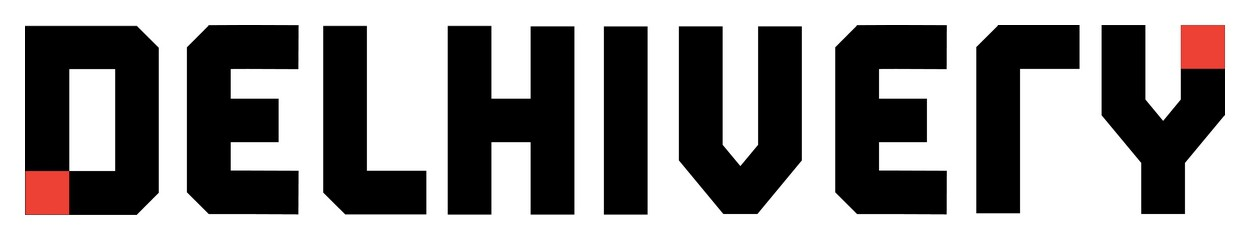

## <font color = Red>**Context** </font>
**Delhivery is the largest and fastest-growing fully integrated player in India by revenue in Fiscal 2021.**

**They aim to build the operating system for commerce, through a combination of world-class infrastructure, logistics operations of the highest quality, and cutting-edge engineering and technology capabilities.**

**The Data team builds intelligence and capabilities using this data that helps them to widen the gap between the quality, efficiency, and profitability of their business versus their competitors.**


## <font color = Red>**Business Problem**</font>
**The company wants to understand and process the data coming out of data engineering pipelines:**
 - **Clean, sanitize and manipulate data to get useful features out of raw fields**
 - **Make sense out of the raw data and help the data science team to build forecasting models on it**


## <font color = Green>**Column Profiling:**</font>

- **data**:	tells whether the data is testing or training data
- **trip_creation_time**:	 Timestamp of trip creation
- **route_schedule_uuid**:	Unique Id for a particular route schedule
- **route_type**:	Transportation type
 - **FTL** : Full Truck Load: FTL shipments get to the destination sooner, as the truck is making no other pickups or drop-offs along the way
 - **Carting**: Handling system consisting of small vehicles (carts)
- **trip_uuid**:	Unique ID given to a particular trip (A trip may include different source and destination centers)
- **source_center**:	Source ID of trip origin
- **source_name**:	Source Name of trip origin
- **destination_cente**:	Destination ID
- **destination_name**:	Destination Name
- **od_start_time**:	Trip start time
- **od_end_time**:	Trip end time
- **start_scan_to_end_scan**:	Time taken to deliver from source to destination
- **is_cutoff**: Unknown field
- **cutoff_factor**: Unknown field
- **cutoff_timestamp**: Unknown field
- **actual_distance_to_destination**: Distance in Kms between source and destination warehouse
- **actual_time**: Actual time taken to complete the delivery (Cumulative)
- **osrm_time**: An open-source routing engine time calculator which computes the shortest path between points in a given map (Includes usual traffic, distance through major and minor roads) and gives the time (Cumulative)
- **osrm_distance**: An open-source routing engine which computes the shortest path between points in a given map (Includes usual traffic, distance through major and minor roads) (Cumulative)
- **factor**: Unknown field
- **segment_actual_time**: This is a segment time. Time taken by the subset of the package delivery
- **segment_osrm_time**: This is the OSRM segment time. Time taken by the subset of the package delivery
- **segment_osrm_distance**: This is the OSRM distance. Distance covered by subset of the package delivery
- **segment_factor**: Unknown field




## 1. Imports

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from scipy import stats
from scipy.stats import ttest_rel, pearsonr
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

## 2. Load data

In [5]:
# Downloding the data
!gdown 1JUdV-RcrF_Z56VHbhHkf6V7vjVsf-5Ka

Downloading...
From: https://drive.google.com/uc?id=1JUdV-RcrF_Z56VHbhHkf6V7vjVsf-5Ka
To: /content/delhivery_data.txt
100% 55.6M/55.6M [00:00<00:00, 151MB/s]


In [6]:
# Loading a CSV file into a pandas DataFrame.
df = pd.read_csv("/content/delhivery_data.txt")

In [7]:
# Viewing the first few rows of a DataFrame.
df.head()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:27:55,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:17:55,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:01:19.505586,27.637279,40.0,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:39:57,36.118028,62.0,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:33:55,39.386040,68.0,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000


In [8]:
# Viewing the last few rows of a DataFrame.
df.tail()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
144862,training,2018-09-20 16:24:28.436231,thanos::sroute:f0569d2f-4e20-4c31-8542-67b86d5...,Carting,trip-153746066843555182,IND131028AAB,Sonipat_Kundli_H (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-20 16:24:28.436231,...,2018-09-20 21:57:20,45.258278,94.0,60.0,67.9280,1.566667,12.0,12.0,8.1858,1.000000
144863,training,2018-09-20 16:24:28.436231,thanos::sroute:f0569d2f-4e20-4c31-8542-67b86d5...,Carting,trip-153746066843555182,IND131028AAB,Sonipat_Kundli_H (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-20 16:24:28.436231,...,2018-09-20 21:31:18,54.092531,120.0,76.0,85.6829,1.578947,26.0,21.0,17.3725,1.238095
144864,training,2018-09-20 16:24:28.436231,thanos::sroute:f0569d2f-4e20-4c31-8542-67b86d5...,Carting,trip-153746066843555182,IND131028AAB,Sonipat_Kundli_H (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-20 16:24:28.436231,...,2018-09-20 21:11:18,66.163591,140.0,88.0,97.0933,1.590909,20.0,34.0,20.7053,0.588235
144865,training,2018-09-20 16:24:28.436231,thanos::sroute:f0569d2f-4e20-4c31-8542-67b86d5...,Carting,trip-153746066843555182,IND131028AAB,Sonipat_Kundli_H (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-20 16:24:28.436231,...,2018-09-20 20:53:19,73.680667,158.0,98.0,111.2709,1.612245,17.0,27.0,18.8885,0.629630
144866,training,2018-09-20 16:24:28.436231,thanos::sroute:f0569d2f-4e20-4c31-8542-67b86d5...,Carting,trip-153746066843555182,IND131028AAB,Sonipat_Kundli_H (Haryana),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-20 16:24:28.436231,...,2018-09-20 16:24:28.436231,70.039010,426.0,95.0,88.7319,4.484211,268.0,9.0,8.8088,29.777778


## 3. Exploratory Data Analysis and Data Cleaning (EDA)

In [9]:
# Retrieving the dimensions of a DataFrame (Rows, Columns).
df.shape

(144867, 24)

In [10]:
# Retrieving the column labels of a DataFrame .
df.columns

Index(['data', 'trip_creation_time', 'route_schedule_uuid', 'route_type',
       'trip_uuid', 'source_center', 'source_name', 'destination_center',
       'destination_name', 'od_start_time', 'od_end_time',
       'start_scan_to_end_scan', 'is_cutoff', 'cutoff_factor',
       'cutoff_timestamp', 'actual_distance_to_destination', 'actual_time',
       'osrm_time', 'osrm_distance', 'factor', 'segment_actual_time',
       'segment_osrm_time', 'segment_osrm_distance', 'segment_factor'],
      dtype='object')

In [73]:
# Retrieving statistics of the numerical columns in a DataFrame.
df.describe().T

,count,mean,min,25%,50%,75%,max,std
start_scan_to_end_scan,113756.0,688.511657,20.0,134.0,315.0,899.0,3802.0,819.620531
actual_distance_to_destination,113756.0,116.687892,9.000045,22.388809,45.062903,154.045775,682.266831,150.553467
actual_time,113756.0,206.988818,9.0,43.0,91.0,264.0,1213.0,252.866299
osrm_time,113756.0,108.020975,6.0,23.0,48.0,134.0,607.0,132.310726
osrm_distance,113756.0,140.470149,9.0082,26.54465,54.98705,174.73075,820.8258,179.85373
segment_actual_time,113756.0,27.631712,-7.0,17.0,26.0,36.0,70.0,14.623144
segment_osrm_time,113756.0,15.656282,0.0,9.0,16.0,20.0,38.0,7.879071
segment_osrm_distance,113756.0,19.418907,0.0,10.9309,22.1897,26.045175,51.4296,9.795437
trip_creation_time_formatted,113756,2018-09-22 11:33:59.569473280,2018-09-12 00:00:16,2018-09-17 01:06:28,2018-09-22 01:48:38,2018-09-27 15:47:09,2018-10-03 23:59:42,NaN
od_start_time_formatted,113756,2018-09-22 15:59:12.900752384,2018-09-12 00:00:16,2018-09-17 06:06:46,2018-09-22 05:53:33,2018-09-27 19:40:10,2018-10-06 04:27:23,NaN


In [12]:
# Display the data type of each column in a DataFrame
df.dtypes

,0
data,object
trip_creation_time,object
route_schedule_uuid,object
route_type,object
trip_uuid,object
source_center,object
source_name,object
destination_center,object
destination_name,object
od_start_time,object


In [13]:
# Display the number of missing values (NaN) in each column of the DataFrame
df.isnull().sum()

,0
data,0
trip_creation_time,0
route_schedule_uuid,0
route_type,0
trip_uuid,0
source_center,0
source_name,293
destination_center,0
destination_name,261
od_start_time,0


In [14]:
# Retrieving summary of a DataFrame.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144867 entries, 0 to 144866
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   data                            144867 non-null  object 
 1   trip_creation_time              144867 non-null  object 
 2   route_schedule_uuid             144867 non-null  object 
 3   route_type                      144867 non-null  object 
 4   trip_uuid                       144867 non-null  object 
 5   source_center                   144867 non-null  object 
 6   source_name                     144574 non-null  object 
 7   destination_center              144867 non-null  object 
 8   destination_name                144606 non-null  object 
 9   od_start_time                   144867 non-null  object 
 10  od_end_time                     144867 non-null  object 
 11  start_scan_to_end_scan          144867 non-null  float64
 12  is_cutoff       

In [15]:
df.head()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:27:55,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:17:55,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:01:19.505586,27.637279,40.0,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:39:57,36.118028,62.0,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:33:55,39.386040,68.0,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000


In [16]:
# Convert to datetime and in corredted format
df["trip_creation_time_formatted"] = pd.to_datetime(df["trip_creation_time"]).dt.strftime("%d-%m-%Y %H:%M:%S")
df["od_start_time_formatted"] = pd.to_datetime(df["od_start_time"]).dt.strftime("%d-%m-%Y %H:%M:%S")
df["od_end_time_formatted"] = pd.to_datetime(df["od_end_time"]).dt.strftime("%d-%m-%Y %H:%M:%S")
df["trip_creation_time_formatted"] = pd.to_datetime(df["trip_creation_time_formatted"], format="%d-%m-%Y %H:%M:%S")
df["od_start_time_formatted"] = pd.to_datetime(df["od_start_time_formatted"], format="%d-%m-%Y %H:%M:%S")
df["od_end_time_formatted"] = pd.to_datetime(df["od_end_time_formatted"], format="%d-%m-%Y %H:%M:%S")

In [17]:
# Drop Duplicated or unnecessary columns
df.drop(columns=["trip_creation_time","od_start_time","od_end_time"],axis=1,inplace = True)

In [18]:
df.head()

,data,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,start_scan_to_end_scan,is_cutoff,...,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor,trip_creation_time_formatted,od_start_time_formatted,od_end_time_formatted
0,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,True,...,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45
1,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,True,...,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45
2,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,True,...,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45
3,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,True,...,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45
4,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,False,...,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144867 entries, 0 to 144866
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   data                            144867 non-null  object        
 1   route_schedule_uuid             144867 non-null  object        
 2   route_type                      144867 non-null  object        
 3   trip_uuid                       144867 non-null  object        
 4   source_center                   144867 non-null  object        
 5   source_name                     144574 non-null  object        
 6   destination_center              144867 non-null  object        
 7   destination_name                144606 non-null  object        
 8   start_scan_to_end_scan          144867 non-null  float64       
 9   is_cutoff                       144867 non-null  bool          
 10  cutoff_factor                   144867 non-null  int64  

In [20]:
df.columns

Index(['data', 'route_schedule_uuid', 'route_type', 'trip_uuid',
       'source_center', 'source_name', 'destination_center',
       'destination_name', 'start_scan_to_end_scan', 'is_cutoff',
       'cutoff_factor', 'cutoff_timestamp', 'actual_distance_to_destination',
       'actual_time', 'osrm_time', 'osrm_distance', 'factor',
       'segment_actual_time', 'segment_osrm_time', 'segment_osrm_distance',
       'segment_factor', 'trip_creation_time_formatted',
       'od_start_time_formatted', 'od_end_time_formatted'],
      dtype='object')

In [21]:
df.drop(columns=["is_cutoff","cutoff_factor","cutoff_timestamp","factor","segment_factor"],axis=1,inplace=True)

In [22]:
# Check for missing values
(df.isnull().sum()/df.shape[0]) * 100

,0
data,0.000000
route_schedule_uuid,0.000000
route_type,0.000000
trip_uuid,0.000000
source_center,0.000000
source_name,0.202254
destination_center,0.000000
destination_name,0.180165
start_scan_to_end_scan,0.000000
actual_distance_to_destination,0.000000


In [23]:
df.shape

(144867, 19)

The columns "source_name" and "destination_name" contain missing data.

We have two options for addressing this issue:
1. Drop the rows with missing values.
2. Fill in the missing values.

Given that there is very little missing data (not even 1 %), we will choose to drop these rows.

In [24]:
df.dropna(subset=["source_name", "destination_name"], axis=0, inplace=True)

In [25]:
(df.isnull().sum()/df.shape[0]) * 100

,0
data,0.0
route_schedule_uuid,0.0
route_type,0.0
trip_uuid,0.0
source_center,0.0
source_name,0.0
destination_center,0.0
destination_name,0.0
start_scan_to_end_scan,0.0
actual_distance_to_destination,0.0


In [26]:
# # Analyze structure of data
print("Shape of the DataFrame:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nSummary Statistics:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nUnique Values in Each Column:")
print(df.nunique())
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataFrame Info:")
print(df.info())

Shape of the DataFrame: (144316, 19)

Data Types:
data                                      object
route_schedule_uuid                       object
route_type                                object
trip_uuid                                 object
source_center                             object
source_name                               object
destination_center                        object
destination_name                          object
start_scan_to_end_scan                   float64
actual_distance_to_destination           float64
actual_time                              float64
osrm_time                                float64
osrm_distance                            float64
segment_actual_time                      float64
segment_osrm_time                        float64
segment_osrm_distance                    float64
trip_creation_time_formatted      datetime64[ns]
od_start_time_formatted           datetime64[ns]
od_end_time_formatted             datetime64[ns]
dtype: object

Summ

## 4. Build some features to prepare the data for actual analysis.

In [27]:
df["destination_name"]

,destination_name
0,Khambhat_MotvdDPP_D (Gujarat)
1,Khambhat_MotvdDPP_D (Gujarat)
2,Khambhat_MotvdDPP_D (Gujarat)
3,Khambhat_MotvdDPP_D (Gujarat)
4,Khambhat_MotvdDPP_D (Gujarat)
...,...
144862,Gurgaon_Bilaspur_HB (Haryana)
144863,Gurgaon_Bilaspur_HB (Haryana)
144864,Gurgaon_Bilaspur_HB (Haryana)
144865,Gurgaon_Bilaspur_HB (Haryana)


In [28]:
# Source city and source state
df["source_city"] = df["source_name"].str.split("_").str[:-1].str.join("_")
df["source_state"] = df["source_name"].str.extract(r"\((.*?)\)")

In [29]:
# Destination city and destination state
df["destination_city"]= df["destination_name"].str.split("_").str[:-1].str.join("_")
df["destination_state"] = df["destination_name"].str.extract(r"\((.*?)\)")[0]

In [30]:
# Trip Creation Day,Trip Creation Month,Trip Creation Year
df["trip_creation_day"]=df["trip_creation_time_formatted"].dt.day
df["trip_creation_month"]=df["trip_creation_time_formatted"].dt.month
df["trip_creation_year"]=df["trip_creation_time_formatted"].dt.year

In [31]:
df.head()

,data,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,start_scan_to_end_scan,actual_distance_to_destination,...,trip_creation_time_formatted,od_start_time_formatted,od_end_time_formatted,source_city,source_state,destination_city,destination_state,trip_creation_day,trip_creation_month,trip_creation_year
0,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,10.435660,...,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018
1,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,18.936842,...,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018
2,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,27.637279,...,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018
3,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,36.118028,...,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018
4,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,39.386040,...,2018-09-20 02:35:36,2018-09-20 03:21:32,2018-09-20 04:47:45,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018


## 5. In-depth analysis and feature engineering
Calculate the time taken between od_start_time and od_end_time and keep it as a feature

In [32]:
df["trip_completion_time"] = df["od_end_time_formatted"] - df["od_start_time_formatted"]

In [33]:
df["time_taken_seconds"] = df["trip_completion_time"].dt.total_seconds()

In [34]:
df["time_taken_hours"] = df["time_taken_seconds"] / 3600
df["time_taken_minutes"] = df["time_taken_seconds"] / 60

In [35]:
df.head()

,data,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,start_scan_to_end_scan,actual_distance_to_destination,...,source_state,destination_city,destination_state,trip_creation_day,trip_creation_month,trip_creation_year,trip_completion_time,time_taken_seconds,time_taken_hours,time_taken_minutes
0,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,10.435660,...,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667
1,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,18.936842,...,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667
2,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,27.637279,...,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667
3,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,36.118028,...,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667
4,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,39.386040,...,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667


## 6. Outliers Treatment
Visual Analysis for Outliers

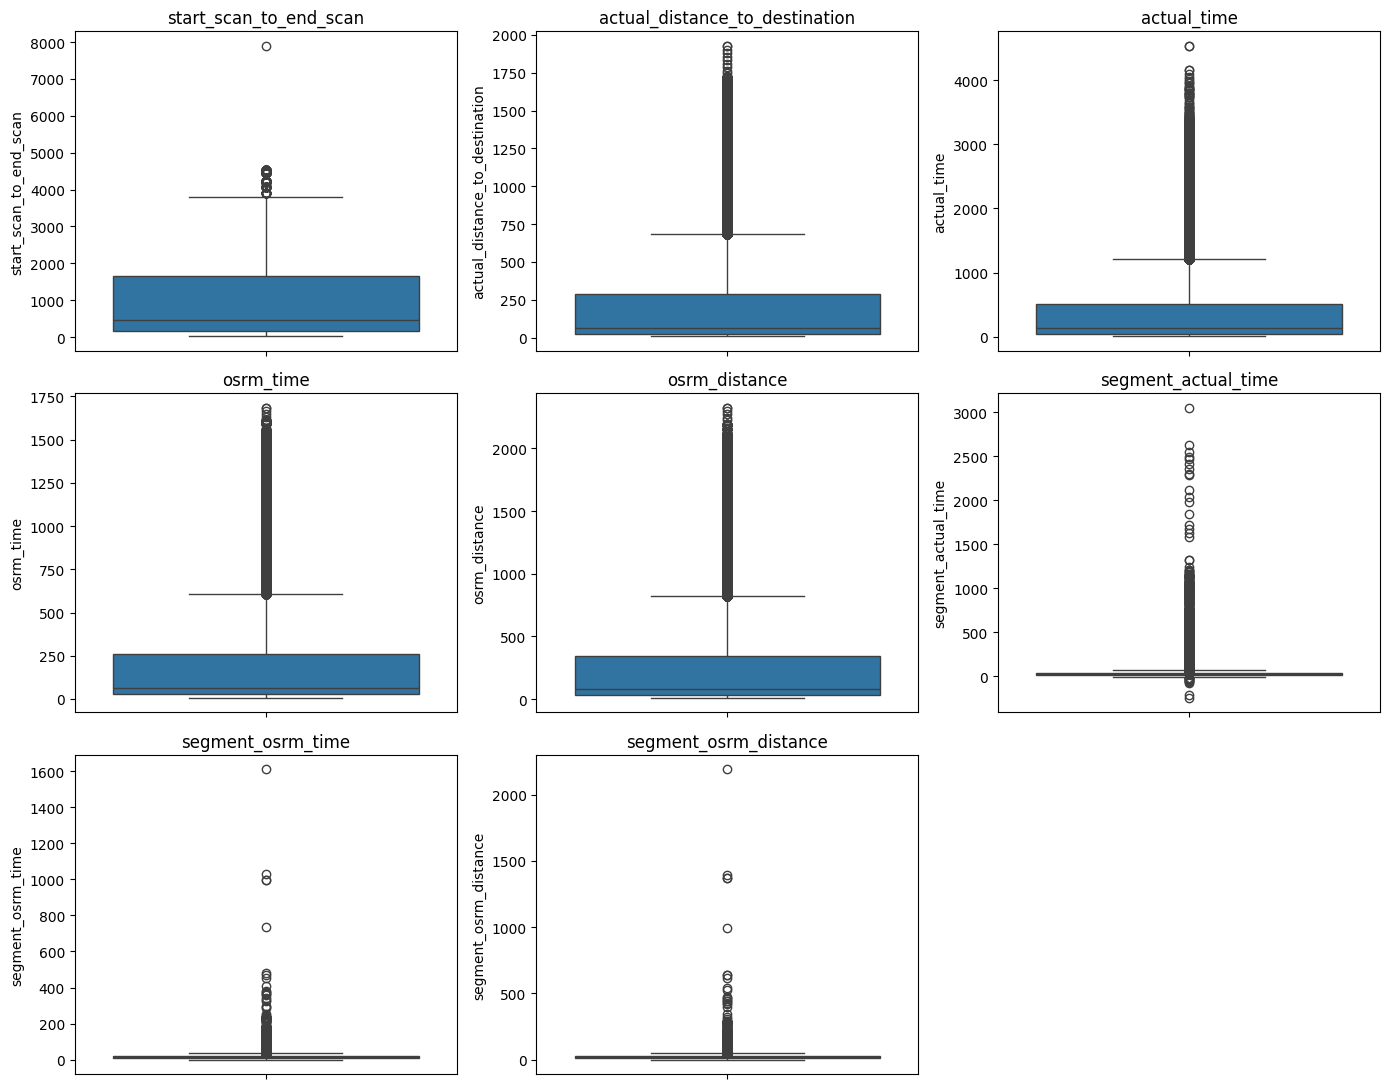

In [36]:
meas_cols = ["start_scan_to_end_scan", "actual_distance_to_destination", "actual_time",
             "osrm_time", "osrm_distance", "segment_actual_time",
             "segment_osrm_time", "segment_osrm_distance"]


numeric_columns = df[meas_cols]

plt.figure(figsize=(14,11))
for i,col in enumerate (numeric_columns.columns):
    plt.subplot(3,3,i+1)
    sns.boxplot(df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

Checking Count of outliers present in Dataset using **IQR: Inter Quartile Range** and remove them.

In [37]:
def identify_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data < lower_bound) | (data > upper_bound)]

outlier_counts = {}  # Dictionary to store outlier counts for each column

for col in numeric_columns.columns:
    outliers = identify_outliers(numeric_columns[col])
    outlier_counts[col] = len(outliers)

# Print the count of outliers for each numerical column
for col, count in outlier_counts.items():
    print(f"Count of outliers present in {col}: {count}")

Count of outliers present in start_scan_to_end_scan: 373
Count of outliers present in actual_distance_to_destination: 17818
Count of outliers present in actual_time: 16507
Count of outliers present in osrm_time: 17406
Count of outliers present in osrm_distance: 17547
Count of outliers present in segment_actual_time: 9262
Count of outliers present in segment_osrm_time: 6348
Count of outliers present in segment_osrm_distance: 4295


In [38]:
df_raw = df.copy()

# Create a DataFrame to store boolean flags for outliers
outlier_flags = pd.DataFrame(False, index=df.index, columns=meas_cols)

# Identify outliers for each numerical column
for col in meas_cols:
    outlier_flags[col] = df.index.isin(identify_outliers(df[col]).index)

# Get the rows that are not outliers
df = df[~outlier_flags.any(axis=1)]
df.shape

(113756, 30)

Lets Convert Categorical (route_type) column into numeric column using one hot encoding

In [39]:
# Create an instance of OneHotEncoder
encoder = OneHotEncoder(sparse_output = False, handle_unknown='ignore')

# Fit and transform the data
one_hot_encoded = encoder.fit_transform(df[["route_type"]])

# Step 1: Create a DataFrame from the one-hot encoded array
one_hot_encoded_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(["route_type"]))

# Step 2: Drop the original 'route_type' column and concatenate
df = pd.concat([df.drop("route_type", axis=1).reset_index(drop=True), one_hot_encoded_df], axis=1)
df.head()

,data,route_schedule_uuid,trip_uuid,source_center,source_name,destination_center,destination_name,start_scan_to_end_scan,actual_distance_to_destination,actual_time,...,destination_state,trip_creation_day,trip_creation_month,trip_creation_year,trip_completion_time,time_taken_seconds,time_taken_hours,time_taken_minutes,route_type_Carting,route_type_FTL
0,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,10.435660,14.0,...,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667,1.0,0.0
1,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,18.936842,24.0,...,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667,1.0,0.0
2,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,27.637279,40.0,...,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667,1.0,0.0
3,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,36.118028,62.0,...,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667,1.0,0.0
4,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),86.0,39.386040,68.0,...,Gujarat,20,9,2018,0 days 01:26:13,5173.0,1.436944,86.216667,1.0,0.0


Compare the difference between time taken minutes and start_scan_to_end_scan. Do hypothesis testing

In [40]:
# Since both Numerical VS Numerical data we will perform Pearsons Correlation test

# Stting Hypothesis
# Null Hypothesis (H0): There is no correlation.
# Alternative Hypothesis (H1): There is a correlation.

# Perform test
r, p_value = pearsonr(df["start_scan_to_end_scan"], df["time_taken_minutes"])

# Output results
print(f"Pearson correlation coefficient: {r}")
print(f"P-value: {p_value}")

# Conclusion result
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant correlation.")
else:
    print("Fail to reject the null hypothesis: No significant correlation.")

print(f"Since Pearson correlation coefficient: {r} is almost 1 there is no diffrence between these two\n")

Pearson correlation coefficient: 0.9999999375217701
P-value: 0.0
Reject the null hypothesis: There is a significant correlation.
Since Pearson correlation coefficient: 0.9999999375217701 is almost 1 there is no diffrence between these two



In [41]:
df.drop(columns=["time_taken_hours","time_taken_seconds","time_taken_minutes"],axis=1,inplace = True)

Lets normalize numerica columns using MinMaxScaler


In [42]:
# # CHANGED: scale only meas_cols (the timedelta column caused your DTypePromotionError)
# # and store the result in df_scaled instead of overwriting df.
# # Scaling each column to its own 0-1 range makes paired t-tests between columns meaningless
# # and caused the inf values in the delay ratio.
# numerical_cols = meas_cols

# # Create the MinMaxScaler
# scaler = MinMaxScaler()

# df_scaled = df.copy()
# df_scaled[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# # Display the modified DataFrame
# df_scaled.head()

,data,route_schedule_uuid,trip_uuid,source_center,source_name,destination_center,destination_name,start_scan_to_end_scan,actual_distance_to_destination,actual_time,...,source_city,source_state,destination_city,destination_state,trip_creation_day,trip_creation_month,trip_creation_year,trip_completion_time,route_type_Carting,route_type_FTL
0,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),0.017451,0.002132,0.004153,...,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,1.0,0.0
1,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),0.017451,0.014759,0.012458,...,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,1.0,0.0
2,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),0.017451,0.027682,0.025748,...,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,1.0,0.0
3,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),0.017451,0.040278,0.044020,...,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,1.0,0.0
4,training,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),0.017451,0.045132,0.049003,...,Anand_VUNagar,Gujarat,Khambhat_MotvdDPP,Gujarat,20,9,2018,0 days 01:26:13,1.0,0.0


## 7. Trip-level aggregation
`actual_time`, `osrm_time`, `osrm_distance` are CUMULATIVE within a trip --> take the last value per
(trip, source, destination) leg, then add the legs.
`segment_*` columns are per-segment pieces -> sum them.
(Your version used mean(), which understates trip totals.)

In [76]:
df_raw = df_raw.sort_values("od_end_time_formatted")

seg = (df_raw.groupby(["trip_uuid", "source_center", "destination_center"])
       .agg(route_type=("route_type", "first"),
            actual_time=("actual_time", "last"),
            osrm_time=("osrm_time", "last"),
            osrm_distance=("osrm_distance", "last"),
            segment_actual_time=("segment_actual_time", "sum"),
            segment_osrm_time=("segment_osrm_time", "sum"),
            segment_osrm_distance=("segment_osrm_distance", "sum"))
       .reset_index())

trip_df = (seg.groupby("trip_uuid")
           .agg(route_type=("route_type", "first"),
                actual_time=("actual_time", "sum"),
                osrm_time=("osrm_time", "sum"),
                osrm_distance=("osrm_distance", "sum"),
                segment_actual_time=("segment_actual_time", "sum"),
                segment_osrm_time=("segment_osrm_time", "sum"),
                segment_osrm_distance=("segment_osrm_distance", "sum")))

print(trip_df.shape)
trip_df.head()

(14787, 7)


,route_type,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance
trip_uuid,,,,,,,
trip-153671041653548748,FTL,917.0,400.0,548.7135,1548.0,1008.0,1320.4733
trip-153671042288605164,Carting,71.0,40.0,49.8775,141.0,65.0,84.1894
trip-153671043369099517,FTL,1212.0,736.0,1001.5184,3308.0,1941.0,2545.2678
trip-153671046011330457,Carting,23.0,9.0,11.9675,59.0,16.0,19.8766
trip-153671052974046625,FTL,232.0,85.0,111.7576,340.0,115.0,146.7919


## 8. Hypothesis test: actual_time vs OSRM time (aggregated by trip_uuid)
Before conducting hypothesis test lets check outliers and treat them.

In [75]:
# CHANGED: aggregated_df now comes from trip_df (correct totals) instead of groupby().mean()
aggregated_df = trip_df[["actual_time", "osrm_time"]].reset_index()
print(aggregated_df)

                     trip_uuid  actual_time  osrm_time
0      trip-153671041653548748        793.0      392.0
1      trip-153671042288605164         71.0       40.0
2      trip-153671043369099517       2304.0     1340.0
3      trip-153671046011330457         23.0        9.0
4      trip-153671052974046625        261.0       91.0
...                        ...          ...        ...
14782  trip-153861095625827784         34.0       29.0
14783  trip-153861104386292051         12.0        7.0
14784  trip-153861106442901555        103.0       32.0
14785  trip-153861115439069069        197.0      129.0
14786  trip-153861118270144424        263.0       63.0

[14787 rows x 3 columns]


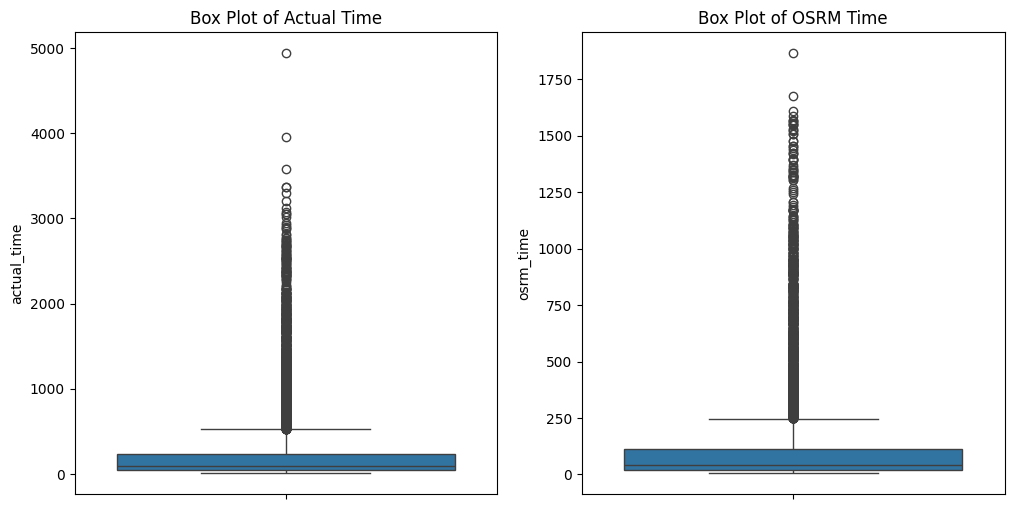

In [45]:
plt.figure(figsize=(12, 6))

# Box plot for actual_time
plt.subplot(1, 2, 1)
sns.boxplot(y=aggregated_df["actual_time"])
plt.title("Box Plot of Actual Time")

# Box plot for osrm_time
plt.subplot(1, 2, 2)
sns.boxplot(y=aggregated_df["osrm_time"])
plt.title("Box Plot of OSRM Time")
plt.show()

In [46]:
actual_time_outliers = identify_outliers(aggregated_df["actual_time"])
osrm_time_outliers = identify_outliers(aggregated_df["osrm_time"])

print("Actual Time Outliers:")
print(actual_time_outliers)

print("\nOSRM Time Outliers:")
print(osrm_time_outliers)

print("\n Count of outliers present in actual and OSRM time ")
print (len(actual_time_outliers),len(osrm_time_outliers))

Actual Time Outliers:
0        1050.0
12        622.0
20        701.0
41       1144.0
43       1672.0
          ...  
14710     534.0
14720    1993.0
14740    1241.0
14764     697.0
14765    1557.0
Name: actual_time, Length: 1455, dtype: float64

OSRM Time Outliers:
0         482.0
30        287.0
41        599.0
43        846.0
46        416.0
          ...  
14716     300.0
14720    1165.0
14722     268.0
14739     274.0
14765     670.0
Name: osrm_time, Length: 1301, dtype: float64

 Count of outliers present in actual and OSRM time 
1455 1301


In [47]:
aggregated_df_cleaned = aggregated_df[~aggregated_df["actual_time"].isin(actual_time_outliers)]
aggregated_df_cleaned = aggregated_df_cleaned[~aggregated_df_cleaned["osrm_time"].isin(osrm_time_outliers)]
aggregated_df_cleaned

,trip_uuid,actual_time,osrm_time
1,trip-153671042288605164,71.0,40.0
2,trip-153671043369099517,359.0,242.0
3,trip-153671046011330457,23.0,9.0
4,trip-153671052974046625,232.0,85.0
5,trip-153671055416136166,52.0,18.0
...,...,...,...
14782,trip-153861095625827784,73.0,51.0
14783,trip-153861104386292051,21.0,12.0
14784,trip-153861106442901555,279.0,48.0
14785,trip-153861115439069069,155.0,97.0


perform a paired t-test to determine if there's a significant difference between the means of actual_time and osrm_time.

In [48]:
# Extract values from cleaned DataFrame
actual_time_cleaned = aggregated_df_cleaned["actual_time"]
osrm_time_cleaned = aggregated_df_cleaned["osrm_time"]

# Perform paired t-test
t_statistic_cleaned, p_value_cleaned = ttest_rel(actual_time_cleaned, osrm_time_cleaned)

print(f"T-statistic (cleaned): {t_statistic_cleaned}\nP-value (cleaned): {p_value_cleaned}")

# Conclusion
if p_value_cleaned < alpha:
    print("Reject the null hypothesis: There is a significant difference.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")

T-statistic (cleaned): 106.41255869161058
P-value (cleaned): 0.0
Mean actual: 120.7 min | Mean OSRM: 57.5 min | Ratio: 2.10x
Reject the null hypothesis: There is a significant difference.


In [49]:
print(aggregated_df_cleaned[['actual_time', 'osrm_time']].describe())

        actual_time     osrm_time
count  13085.000000  13085.000000
mean     120.671379     57.478793
std      109.365361     53.570556
min        9.000000      6.000000
25%       39.000000     19.000000
50%       78.000000     35.000000
75%      173.000000     81.000000
max      529.000000    246.000000


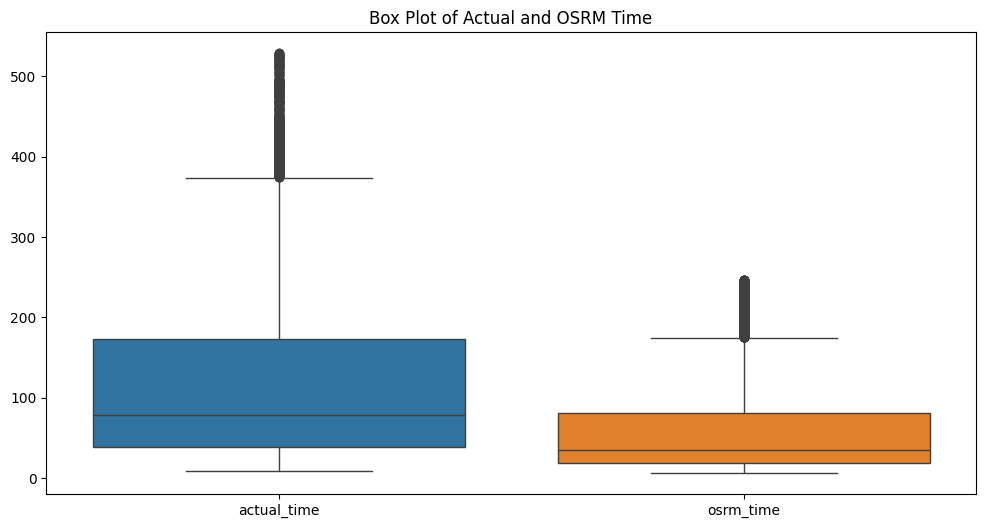

In [50]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=aggregated_df_cleaned[["actual_time", "osrm_time"]])
plt.title("Box Plot of Actual and OSRM Time")
plt.show()

## 9. Hypothesis test: actual_time vs segment actual time (aggregated by trip_uuid)

In [51]:
aggregated_df = trip_df[["actual_time", "segment_actual_time"]].reset_index()
print(aggregated_df)

                     trip_uuid  actual_time  segment_actual_time
0      trip-153671041653548748       1050.0               1548.0
1      trip-153671042288605164         71.0                141.0
2      trip-153671043369099517        359.0               3308.0
3      trip-153671046011330457         23.0                 59.0
4      trip-153671052974046625        232.0                340.0
...                        ...          ...                  ...
14782  trip-153861095625827784         73.0                 82.0
14783  trip-153861104386292051         21.0                 21.0
14784  trip-153861106442901555        279.0                281.0
14785  trip-153861115439069069        155.0                258.0
14786  trip-153861118270144424        263.0                274.0

[14787 rows x 3 columns]


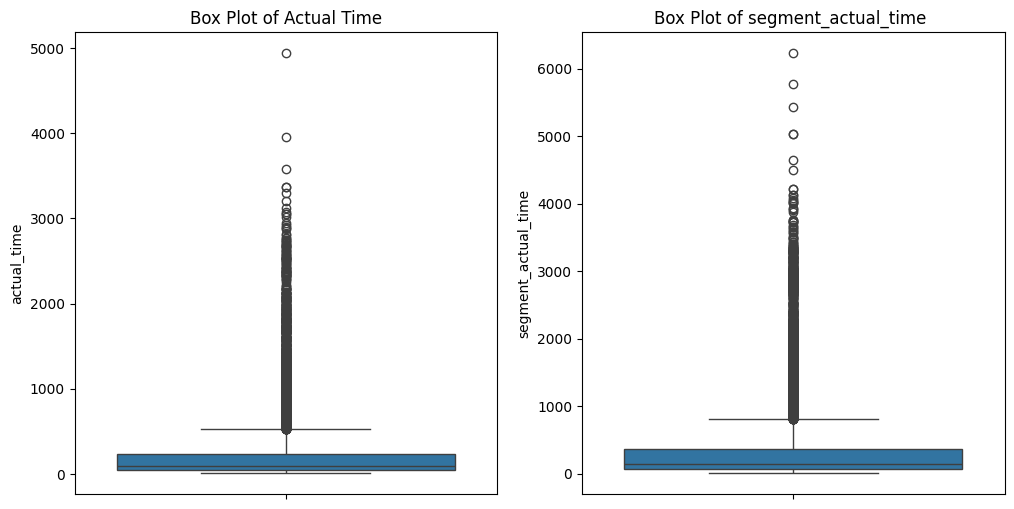

In [52]:
plt.figure(figsize=(12, 6))

# Box plot for actual_time
plt.subplot(1, 2, 1)
sns.boxplot(y=aggregated_df["actual_time"])
plt.title("Box Plot of Actual Time")

# Box plot for segment_actual_time
plt.subplot(1, 2, 2)
sns.boxplot(y=aggregated_df["segment_actual_time"])
plt.title("Box Plot of segment_actual_time ")
plt.show()

In [53]:
actual_time_outliers = identify_outliers(aggregated_df["actual_time"])
segment_actual_time_outliers = identify_outliers(aggregated_df["segment_actual_time"])

print("Actual Time Outliers:")
print(actual_time_outliers)

print("\nsegment actual time Outliers:")
print(segment_actual_time_outliers)

print("\n Count of outliers present in actual and segment actual time time ")
print (len(actual_time_outliers),len(segment_actual_time_outliers))

Actual Time Outliers:
0        1050.0
12        622.0
20        701.0
41       1144.0
43       1672.0
          ...  
14710     534.0
14720    1993.0
14740    1241.0
14764     697.0
14765    1557.0
Name: actual_time, Length: 1455, dtype: float64

segment actual time Outliers:
0        1548.0
2        3308.0
20        843.0
41       2073.0
43       1963.0
          ...  
14734    1125.0
14739    3268.0
14740    1292.0
14764     845.0
14765    1660.0
Name: segment_actual_time, Length: 1644, dtype: float64

 Count of outliers present in actual and segment actual time time 
1455 1644


In [54]:
aggregated_df_cleaned = aggregated_df[~aggregated_df["actual_time"].isin(actual_time_outliers)]
aggregated_df_cleaned = aggregated_df_cleaned[~aggregated_df_cleaned["segment_actual_time"].isin(segment_actual_time_outliers)]
aggregated_df_cleaned

,trip_uuid,actual_time,segment_actual_time
1,trip-153671042288605164,71.0,141.0
3,trip-153671046011330457,23.0,59.0
4,trip-153671052974046625,232.0,340.0
5,trip-153671055416136166,52.0,60.0
6,trip-153671066201138152,24.0,24.0
...,...,...,...
14782,trip-153861095625827784,73.0,82.0
14783,trip-153861104386292051,21.0,21.0
14784,trip-153861106442901555,279.0,281.0
14785,trip-153861115439069069,155.0,258.0


perform a paired t-test to compare the two sets of aggregated values since they are related.
Null Hypothesis (H0): There is no significant difference between the actual delivery time and the segment delivery time.
Alternative Hypothesis (H1): There is a significant difference between the actual delivery time and the segment delivery time.

In [55]:
# Extract values from cleaned DataFrame
actual_time_cleaned = aggregated_df_cleaned["actual_time"]
segment_actual_time_cleaned = aggregated_df_cleaned["segment_actual_time"]

# Perform paired t-test
t_statistic_cleaned, p_value_cleaned = stats.ttest_rel(actual_time_cleaned, segment_actual_time_cleaned)

print(f"T-statistic (cleaned): {t_statistic_cleaned}\nP-value (cleaned): {p_value_cleaned}")

# Conclusion
if p_value_cleaned < alpha:
    print("Reject the null hypothesis: There is a significant difference.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")

T-statistic (cleaned): -71.79099276082289
P-value (cleaned): 0.0
Mean actual: 120.0 min | Mean segment sum: 180.6 min
Reject the null hypothesis: There is a significant difference.


## 10. Hypothesis test: OSRM distance vs segment OSRM distance (aggregated by trip_uuid)

In [56]:
aggregated_df = trip_df[["osrm_distance", "segment_osrm_distance"]]
aggregated_df

,osrm_distance,segment_osrm_distance
trip_uuid,,
trip-153671041653548748,662.7858,1320.4733
trip-153671042288605164,49.8775,84.1894
trip-153671043369099517,306.5504,2545.2678
trip-153671046011330457,11.9675,19.8766
trip-153671052974046625,111.7576,146.7919
...,...,...
trip-153861095625827784,64.6188,64.8551
trip-153861104386292051,16.0882,16.0883
trip-153861106442901555,58.7190,104.8866


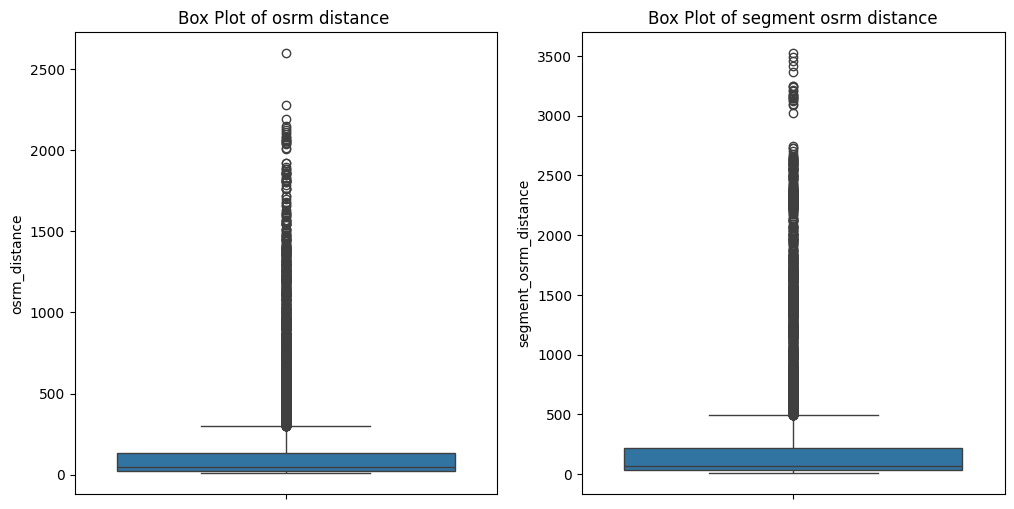

In [57]:
plt.figure(figsize=(12, 6))

# Box plot for osrm_distance
plt.subplot(1, 2, 1)
sns.boxplot(y=aggregated_df["osrm_distance"])
plt.title("Box Plot of osrm distance ")

# Box plot for segment_osrm_distance
plt.subplot(1, 2, 2)
sns.boxplot(y=aggregated_df["segment_osrm_distance"])
plt.title("Box Plot of segment osrm distance")
plt.show()

In [58]:
osrm_distance_outliers = identify_outliers(aggregated_df["osrm_distance"])
segment_osrm_distance_outliers = identify_outliers(aggregated_df["segment_osrm_distance"])

print("osrm distance Outliers:")
print(osrm_distance_outliers)

print("\nsegment osrm distance Outliers:")
print(segment_osrm_distance_outliers)

print("\n Count of outliers present in osrm and segment osrm distance")
print (len(osrm_distance_outliers),len(segment_osrm_distance_outliers))

osrm distance Outliers:
trip_uuid
trip-153671041653548748     662.7858
trip-153671043369099517     306.5504
trip-153671321710455800     811.8706
trip-153671328307356992    1173.2988
trip-153671379462714253     551.8144
                             ...    
trip-153860665408396316     316.9524
trip-153860698042160875    1605.0836
trip-153860723585992237     316.1613
trip-153860879439383883     349.5704
trip-153861014185597051     926.3756
Name: osrm_distance, Length: 1313, dtype: float64

segment osrm distance Outliers:
trip_uuid
trip-153671041653548748    1320.4733
trip-153671043369099517    2545.2678
trip-153671121411074590     623.3792
trip-153671320412492075     596.8154
trip-153671321710455800    1360.3053
                             ...    
trip-153860570045461434    1288.2827
trip-153860698042160875    1747.4544
trip-153860840187622919     666.8525
trip-153860879439383883    2600.9869
trip-153861014185597051    1166.3614
Name: segment_osrm_distance, Length: 1550, dtype: float64



In [59]:
aggregated_df_cleaned = aggregated_df[~aggregated_df["osrm_distance"].isin(osrm_distance_outliers)]
aggregated_df_cleaned = aggregated_df_cleaned[~aggregated_df_cleaned["segment_osrm_distance"].isin(segment_osrm_distance_outliers)]
aggregated_df_cleaned

,osrm_distance,segment_osrm_distance
trip_uuid,,
trip-153671042288605164,49.8775,84.1894
trip-153671046011330457,11.9675,19.8766
trip-153671052974046625,111.7576,146.7919
trip-153671055416136166,21.9728,28.0647
trip-153671066201138152,12.0184,12.0184
...,...,...
trip-153861095625827784,64.6188,64.8551
trip-153861104386292051,16.0882,16.0883
trip-153861106442901555,58.7190,104.8866


Conduct Hypothesis test
* Null Hypothesis (H0): There is no significant difference between the aggregated OSRM distance and the segment OSRM distance.
* Alternative Hypothesis (H1): There is a significant difference between the two distances.

In [60]:
# Extract values from cleaned DataFrame
osrm_distance_cleaned = aggregated_df_cleaned["osrm_distance"]
segment_osrm_distance_cleaned = aggregated_df_cleaned["segment_osrm_distance"]

# Perform paired t-test
t_statistic_cleaned, p_value_cleaned = ttest_rel(osrm_distance_cleaned, segment_osrm_distance_cleaned)

print(f"T-statistic (cleaned): {t_statistic_cleaned}\nP-value (cleaned): {p_value_cleaned}")


# Conclusion
if p_value_cleaned < alpha:
    print("Reject the null hypothesis: There is a significant difference.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")

T-statistic (cleaned): -75.946312957799
P-value (cleaned): 0.0
Mean OSRM distance: 66.1 km | Mean segment sum: 101.1 km
Reject the null hypothesis: There is a significant difference.


## 11. Hypothesis test: OSRM time vs segment OSRM time (aggregated by trip_uuid)

In [61]:
aggregated_df = trip_df[["osrm_time", "segment_osrm_time"]]
aggregated_df

,osrm_time,segment_osrm_time
trip_uuid,,
trip-153671041653548748,482.0,1008.0
trip-153671042288605164,40.0,65.0
trip-153671043369099517,242.0,1941.0
trip-153671046011330457,9.0,16.0
trip-153671052974046625,85.0,115.0
...,...,...
trip-153861095625827784,51.0,62.0
trip-153861104386292051,12.0,11.0
trip-153861106442901555,48.0,88.0


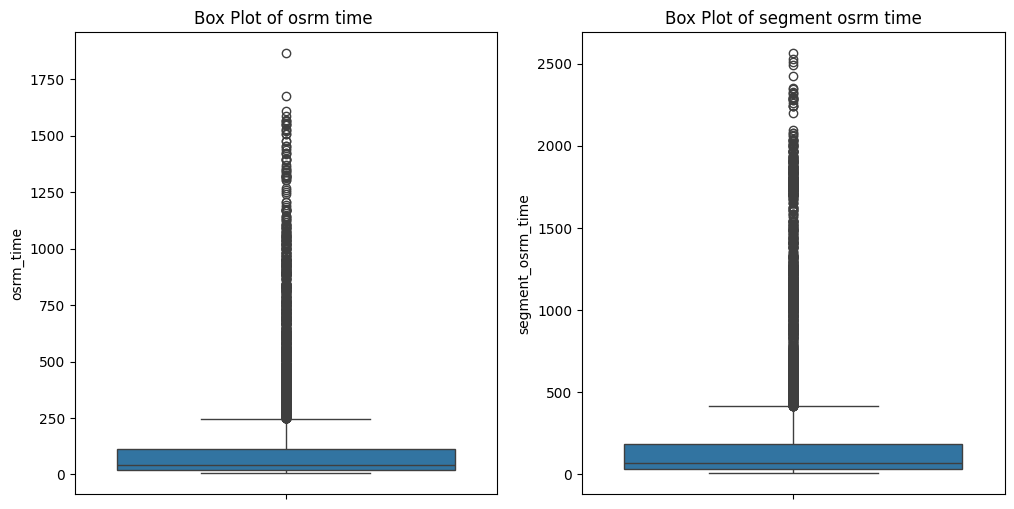

In [62]:
plt.figure(figsize=(12, 6))

# Box plot for osrm_time
plt.subplot(1, 2, 1)
sns.boxplot(y=aggregated_df["osrm_time"])
plt.title("Box Plot of osrm time ")

# Box plot for segment_osrm_time
plt.subplot(1, 2, 2)
sns.boxplot(y=aggregated_df["segment_osrm_time"])
plt.title("Box Plot of segment osrm time")
plt.show()

In [63]:
osrm_time_outliers = identify_outliers(aggregated_df["osrm_time"])
segment_osrm_time_outliers = identify_outliers(aggregated_df["segment_osrm_time"])

print("osrm time Outliers:")
print(osrm_time_outliers)

print("\nsegment osrm time Outliers:")
print(segment_osrm_time_outliers)

print("\n Count of outliers present in osrm and segment osrm time")
print (len(osrm_time_outliers),len(segment_osrm_time_outliers))

osrm time Outliers:
trip_uuid
trip-153671041653548748     482.0
trip-153671277074687197     287.0
trip-153671321710455800     599.0
trip-153671328307356992     846.0
trip-153671379462714253     416.0
                            ...  
trip-153860665408396316     300.0
trip-153860698042160875    1165.0
trip-153860723585992237     268.0
trip-153860879439383883     274.0
trip-153861014185597051     670.0
Name: osrm_time, Length: 1301, dtype: float64

segment osrm time Outliers:
trip_uuid
trip-153671041653548748    1008.0
trip-153671043369099517    1941.0
trip-153671121411074590     492.0
trip-153671320412492075     471.0
trip-153671321710455800    1003.0
                            ...  
trip-153860570045461434     955.0
trip-153860698042160875    1349.0
trip-153860840187622919     467.0
trip-153860879439383883    1996.0
trip-153861014185597051     891.0
Name: segment_osrm_time, Length: 1485, dtype: float64

 Count of outliers present in osrm and segment osrm time
1301 1485


In [64]:
aggregated_df_cleaned = aggregated_df[~aggregated_df["osrm_time"].isin(osrm_time_outliers)]
aggregated_df_cleaned = aggregated_df_cleaned[~aggregated_df_cleaned["segment_osrm_time"].isin(segment_osrm_time_outliers)]
aggregated_df_cleaned

,osrm_time,segment_osrm_time
trip_uuid,,
trip-153671042288605164,40.0,65.0
trip-153671046011330457,9.0,16.0
trip-153671052974046625,85.0,115.0
trip-153671055416136166,18.0,23.0
trip-153671066201138152,13.0,13.0
...,...,...
trip-153861095625827784,51.0,62.0
trip-153861104386292051,12.0,11.0
trip-153861106442901555,48.0,88.0


Conduct Hypothesis test
* Null Hypothesis (H0): There is no significant difference between the aggregated OSRM time and the segment OSRM time.
* Alternative Hypothesis (H1): There is a significant difference between the two times.

In [65]:
# Extract values from cleaned DataFrame
osrm_time_cleaned = aggregated_df_cleaned["osrm_time"]
segment_osrm_time_cleaned = aggregated_df_cleaned["segment_osrm_time"]

# Perform paired t-test
t_statistic_cleaned, p_value_cleaned = ttest_rel(osrm_time_cleaned, segment_osrm_time_cleaned)

print(f"T-statistic (cleaned): {t_statistic_cleaned}\nP-value (cleaned): {p_value_cleaned}")


# Conclusion
if p_value_cleaned < alpha:
    print("Reject the null hypothesis: There is a significant difference.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")

T-statistic (cleaned): -78.3355210297485
P-value (cleaned): 0.0
Mean OSRM time: 57.0 min | Mean segment sum: 88.9 min
Reject the null hypothesis: There is a significant difference.


## 12. Business insights

In [66]:
df_raw["destination_state"].nunique()

32

In [67]:
# Top 10 states with highest Orders
top_states = df_raw.groupby("destination_state")["trip_uuid"].nunique().sort_values(ascending=False).head(10)
print(top_states)

destination_state
Maharashtra      2637
Karnataka        2425
Haryana          1800
Tamil Nadu       1097
Uttar Pradesh     882
Telangana         856
Gujarat           791
West Bengal       713
Punjab            693
Delhi             674
Name: trip_uuid, dtype: int64


In [68]:
# Busiest corridors (source city --> destination city)
corridors = (df_raw.groupby(["source_city", "destination_city"])["trip_uuid"]
             .nunique().sort_values(ascending=False).head(10))
print(corridors)

source_city         destination_city  
Bangalore_Nelmngla  Bengaluru_KGAirprt    151
                    Bengaluru_Bomsndra    127
Bengaluru_Bomsndra  Bengaluru_KGAirprt    121
Bengaluru_KGAirprt  Bangalore_Nelmngla    108
Pune_Tathawde       Bhiwandi_Mankoli      107
Bhiwandi_Mankoli                          105
Bengaluru_Bomsndra  Bangalore_Nelmngla    102
Delhi_Gateway       Gurgaon_Bilaspur      100
Mumbai_Chndivli     Bhiwandi_Mankoli       99
Gurgaon_Bilaspur    Sonipat_Kundli         92
Name: trip_uuid, dtype: int64


In [69]:
# FTL vs Carting share of trips
print(trip_df["route_type"].value_counts(normalize=True))

route_type
Carting    0.602286
FTL        0.397714
Name: proportion, dtype: float64


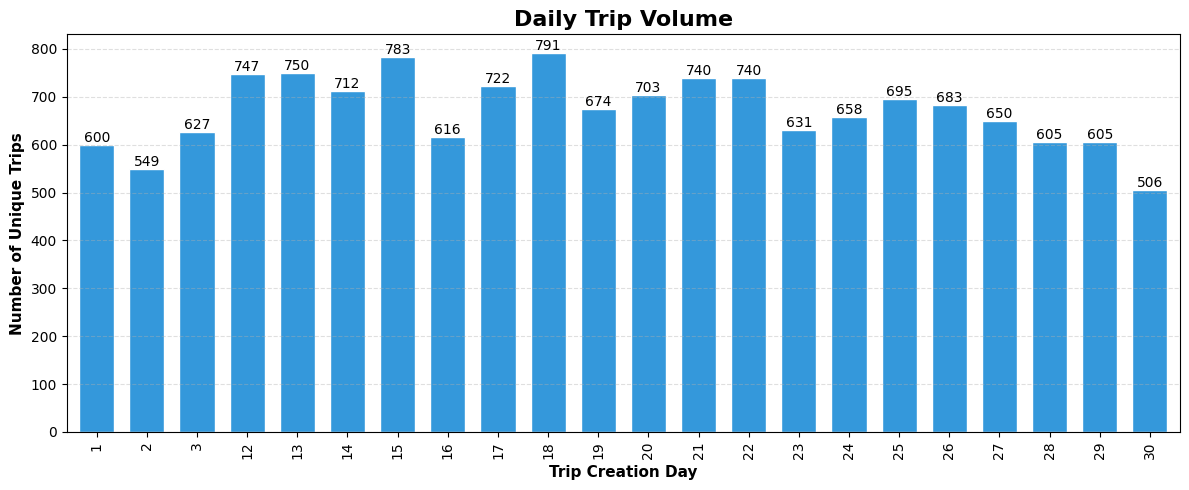

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

# Trips per day
trips_per_day = df_raw.groupby("trip_creation_day")["trip_uuid"].nunique()

# Create the chart
plt.figure(figsize=(12, 5))

ax = trips_per_day.plot(
    kind="bar",
    color="#3498DB",
    edgecolor="white",
    width=0.7
)

# Titles and labels
plt.title("Daily Trip Volume", fontsize=16, fontweight="bold")
plt.xlabel("Trip Creation Day", fontsize=11, fontweight="bold")
plt.ylabel("Number of Unique Trips", fontsize=11, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add values above each bar
for container in ax.containers:
    ax.bar_label(container)


plt.tight_layout()
plt.show()

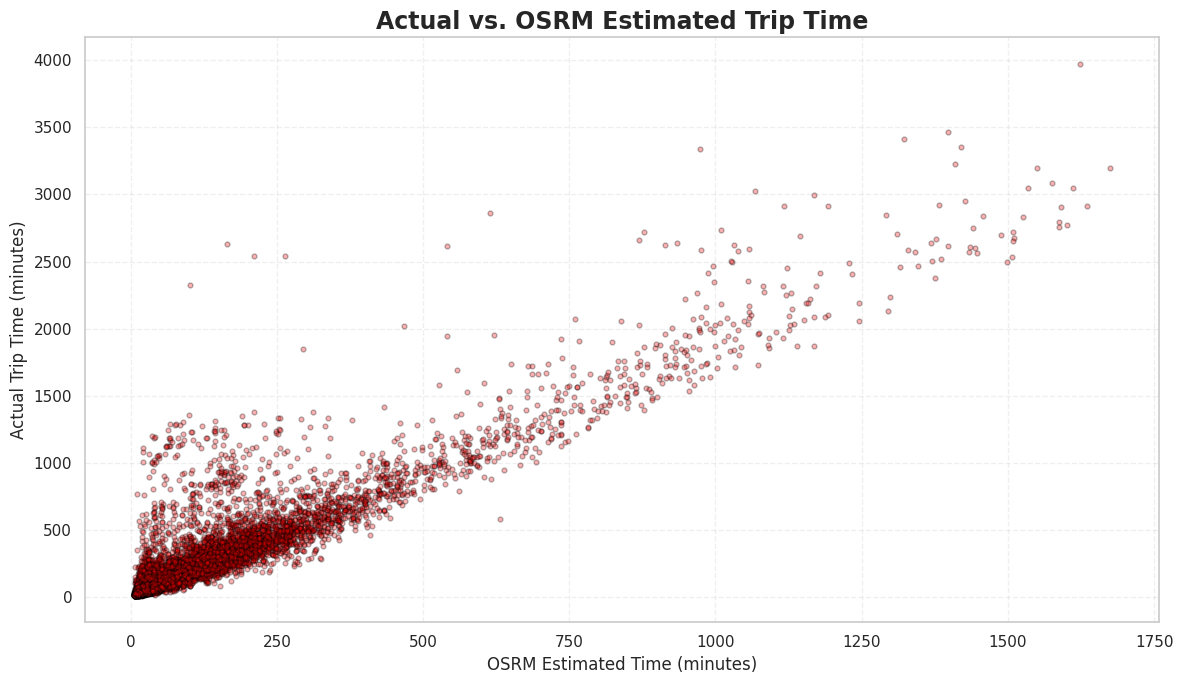

In [92]:
# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Scatter plot
ax.scatter(
    plot_df["osrm_time"],
    plot_df["actual_time"],
    s=12,
    alpha=0.3,
    edgecolors="black",
    color = "red"
)


# Titles and labels
ax.set_title(
    "Actual vs. OSRM Estimated Trip Time",
    fontsize=17,
    fontweight="bold")

ax.set_xlabel("OSRM Estimated Time (minutes)", fontsize=12)
ax.set_ylabel("Actual Trip Time (minutes)", fontsize=12)



# Grid and legend
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


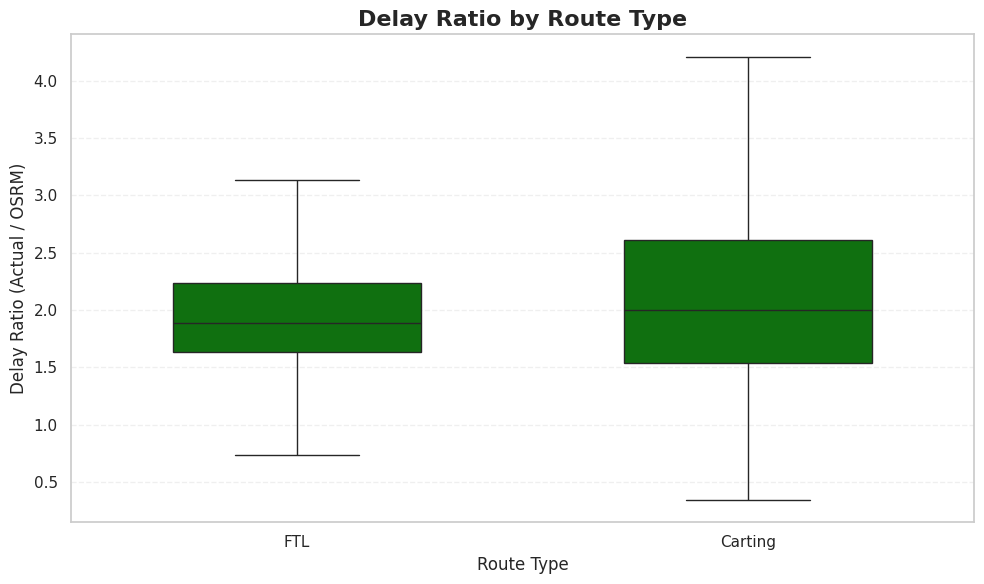

In [96]:
# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

ratio_df = trip_df[trip_df["delay_ratio"].between(0, 5)]
# Create box plot
sns.boxplot(
    data=ratio_df,
    x="route_type",
    y="delay_ratio",
    width=0.55,
    showfliers=False,
    color = "green"
)


# Titles and labels
ax.set_title(
    "Delay Ratio by Route Type",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Route Type", fontsize=12)
ax.set_ylabel("Delay Ratio (Actual / OSRM)", fontsize=12)

# Formatting
ax.grid(axis="y", linestyle="--", alpha=0.3)



plt.tight_layout()
plt.show()


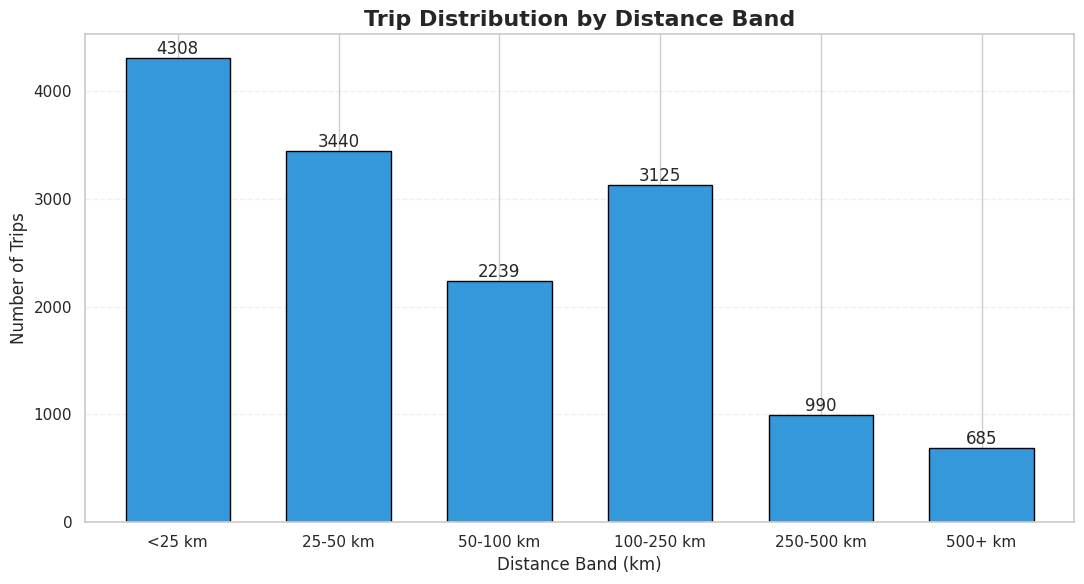

In [107]:
# Define distance bins and labels
bins = [0, 25, 50, 100, 250, 500, np.inf]
labels = ["<25 km", "25-50 km", "50-100 km", "100-250 km", "250-500 km", "500+ km"]

# Create distance bands
trip_df["distance_band"] = pd.cut(
    trip_df["osrm_distance"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

distance_counts = trip_df["distance_band"].value_counts(sort=False)


# Create figure
plt.figure(figsize=(11, 6))

# Plot bar chart
ax = distance_counts.plot(
    kind="bar",
    width=0.65,
    color="#3498DB",
    edgecolor="black"
)

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container)

# Titles and labels
ax.set_title(
    "Trip Distribution by Distance Band",
    fontsize=16,
    fontweight="bold")

ax.set_xlabel("Distance Band (km)", fontsize=12)
ax.set_ylabel("Number of Trips", fontsize=12)

# Formatting
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation = 00)
plt.tight_layout()
plt.show()


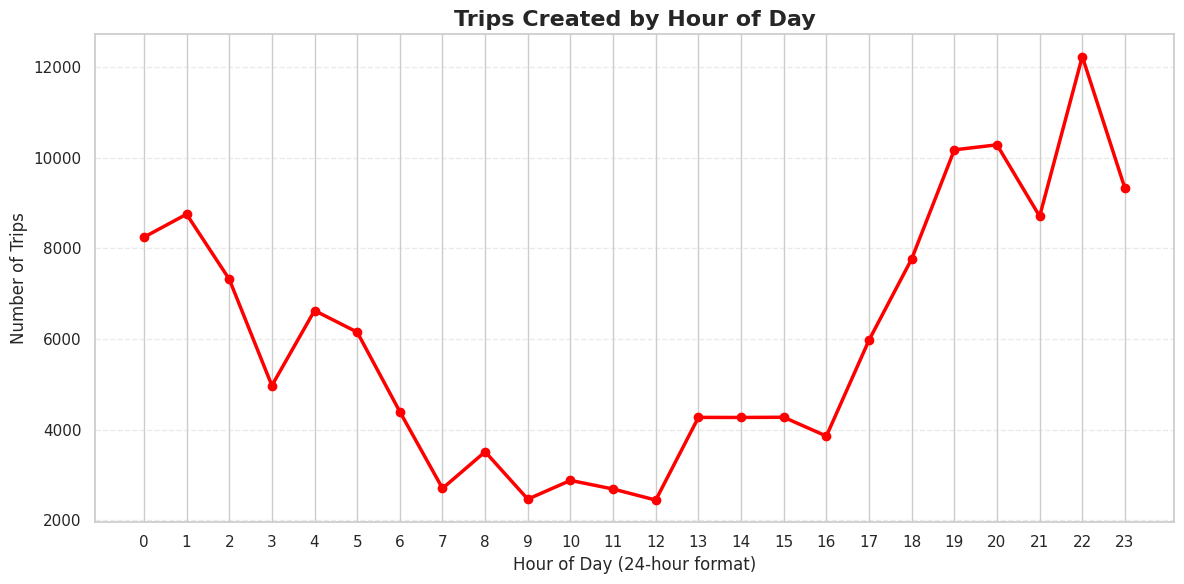

In [113]:
# Count trips by hour
hourly = (df_raw["trip_creation_time_formatted"].dt.hour.value_counts().sort_index())


# Create figure
plt.figure(figsize=(12, 6))

# Plot line chart
ax = hourly.plot(
    kind="line",
    color="Red",
    linewidth=2.5,
    marker="o",
    markersize=6
)

# Add titles and labels
plt.title(
    "Trips Created by Hour of Day",
    fontsize=16,
    fontweight="bold")

plt.xlabel("Hour of Day (24-hour format)", fontsize=12)
plt.ylabel("Number of Trips", fontsize=12)

# Display all 24 hours
plt.xticks(range(24))

# Add gridlines
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Formatting
plt.tight_layout()
plt.show()

## **Business Insights**

- **ETA estimates need to be more realistic:** On average, trips are taking around twice as long as the OSRM estimates. This suggests that actual travel time is affected by more than just the route and distance.

- **Carting trips have more variation in delays:** Delivery times for Carting are less consistent, making it harder to predict when these trips will be completed.

- **A few major hubs handle a large share of operations:** Bengaluru, the Bhiwandi - Mumbai - Pune region, and Delhi-NCR stand out. Keeping track of vehicle availability and workload in these areas could help operations run more smoothly.

- **Most trips are short-distance:** Since the majority of trips are under 100 km, even small improvements in local transport, loading, and unloading could make a noticeable difference.

- **Trip activity changes throughout the day:** More trips are created during the evening and night, while Sundays are generally free. This pattern can help with planning staff and vehicle availability.

## **Recommendations**

1. **Fix the ETA estimates:** Actual trips are taking almost twice as long as OSRM predicts. I would use the current estimates as a baseline and build a model using actual trip time, distance, route type, and trip creation hour to get more realistic delivery estimates.

2. **Investigate delayed trips:** Start by checking trips where actual time is more than three times the estimated time. Looking at these cases individually could help identify whether the delay happened during transit, loading, unloading, or waiting.

3. **Focus on busy locations:** Bengaluru, Bhiwandi - Mumbai - Pune, and Delhi-NCR have several busy routes. These locations are worth looking at first when planning vehicles, staff, and handling capacity.

4. **Improve short-distance deliveries:** Since most trips cover less than 100 km, even small improvements in loading, unloading, and vehicle utilization could make a difference to overall efficiency.

5. **Plan around peak hours:** Trip creation is highest between 5 PM and 2 AM. Staffing and vehicle availability should reflect this pattern, while quieter hours can be used for maintenance and other tasks. Sunday staffing can also be adjusted based on demand.

6. **Check the duration columns:** I would verify how actual time and segment time are calculated. If these fields do not match as expected, it could affect the analysis and any model built from the data.

